# 02 – CT analysis

Analysis of the helical CT scan of phantom 3A.

## Setup

Imports, project paths and our own functions from `src/`. `autoreload` makes changes in `src/` load automatically without restarting the kernel.

In [75]:
# === Autoreload ===
%load_ext autoreload
%autoreload 2

# === Imports ===
import sys
sys.path.append("..")

from pathlib import Path
from scipy import ndimage
from skimage.morphology import convex_hull_image
import matplotlib.pyplot as plt
import pydicom
import numpy as np
import pandas as pd


# === Functions ===
from src.data_io import load_series, save_table, save_figure
from src.viewers import viewer, plane_names, first_header

# === Path ===
RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")

CT_DIR     = RAW / "CT"
CT_HELICAL = CT_DIR / "Helical"      # Main dataset
CT_AXIAL_1 = CT_DIR / "Axial_1"      # Short axial scans 
CT_AXIAL_2 = CT_DIR / "Axial_2"

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---

## Step 1: Load CT data
Loads the helical CT series as a 3D volume in Hounsfield units, sorted by slice position.

In [76]:
ct, ct_spacing = load_series(CT_HELICAL)            # Load the helical CT series as a 3D volume in HU, sorted by slice position
ct_names = plane_names(first_header(CT_HELICAL))    # Get the names of the planes perpendicular to the patient axes

shape = ct.shape

print(f"Shape (slices, rows, cols): {ct.shape}")
print(f"Voxel spacing [mm]: {ct_spacing}")
print(f"Planes: {str(ct_names)[1:-1]}")

Shape (slices, rows, cols): (522, 512, 512)
Voxel spacing [mm]: (0.625, 0.585938, 0.585938)
Planes: 'Axial', 'Coronal', 'Sagittal'


Look at the full volume:

In [77]:
viewer(ct, ct_spacing, names=ct_names, title="CT Helical - full volume", modality="CT")

---

## Step 2: Locating the phantoms

The CT contains eight phantoms (A1–A8), placed as four stacks of two boxes. Each stack is found as a connected region denser than air (> -500 HU), with the table removed (rows ≥ `TABLE_ROW`). Holes are filled, so air inside a phantom counts as part of it, and regions smaller than `MIN_SIZE` voxels are ignored.

Because the boxes in a stack touch each other, each stack is detected as one region. Each stack is then split into a top and a bottom box at the row with the least material between them (the gap at the lid).

In [78]:
TABLE_ROW    = 340            # Rows from here down are the table (check in the axial view)
FILL_RANGE   = (-50, 300)     # HU range of the water-like filling (walls are below, objects may be above)
MIN_SIZE     = 100000         # Minimum size of a box filling (voxels)

# ---------------------------------------------------------------------------
# 1. Mask of water-like voxels (the filling inside each box)
# ---------------------------------------------------------------------------
mask = (ct > FILL_RANGE[0]) & (ct < FILL_RANGE[1])
mask[:, TABLE_ROW:, :] = False                      # Remove the table

# ---------------------------------------------------------------------------
# 2. Break thin connections and fill holes left by objects
# ---------------------------------------------------------------------------
mask = ndimage.binary_opening(mask, iterations=2)
mask = ndimage.binary_fill_holes(mask)

# ---------------------------------------------------------------------------
# 3. Label connected regions and keep the large ones (one per box)
# ---------------------------------------------------------------------------
labels, n = ndimage.label(mask)
sizes = ndimage.sum(mask, labels, range(1, n + 1))
fills = [i + 1 for i, s in enumerate(sizes) if s > MIN_SIZE]
boxes = ndimage.find_objects(labels)

print(f"{n} regions found, {len(fills)} box fillings")
for i in fills:
    sz, sy, sx = boxes[i - 1]
    print(f"Box {i:2d}: z {sz.start:3d}-{sz.stop:3d}, y {sy.start:3d}-{sy.stop:3d}, x {sx.start:3d}-{sx.stop:3d}")

47 regions found, 8 box fillings
Box  7: z  32-228, y 179-253, x 105-221
Box  8: z  32-229, y 263-339, x 108-224
Box  9: z  38-233, y 184-253, x 269-384
Box 10: z  40-236, y 271-340, x 265-384
Box 26: z 291-487, y 183-252, x 112-230
Box 28: z 295-490, y 181-253, x 271-386
Box 29: z 295-491, y 266-340, x 267-383
Box 30: z 297-492, y 269-339, x 113-229


Check the detection:

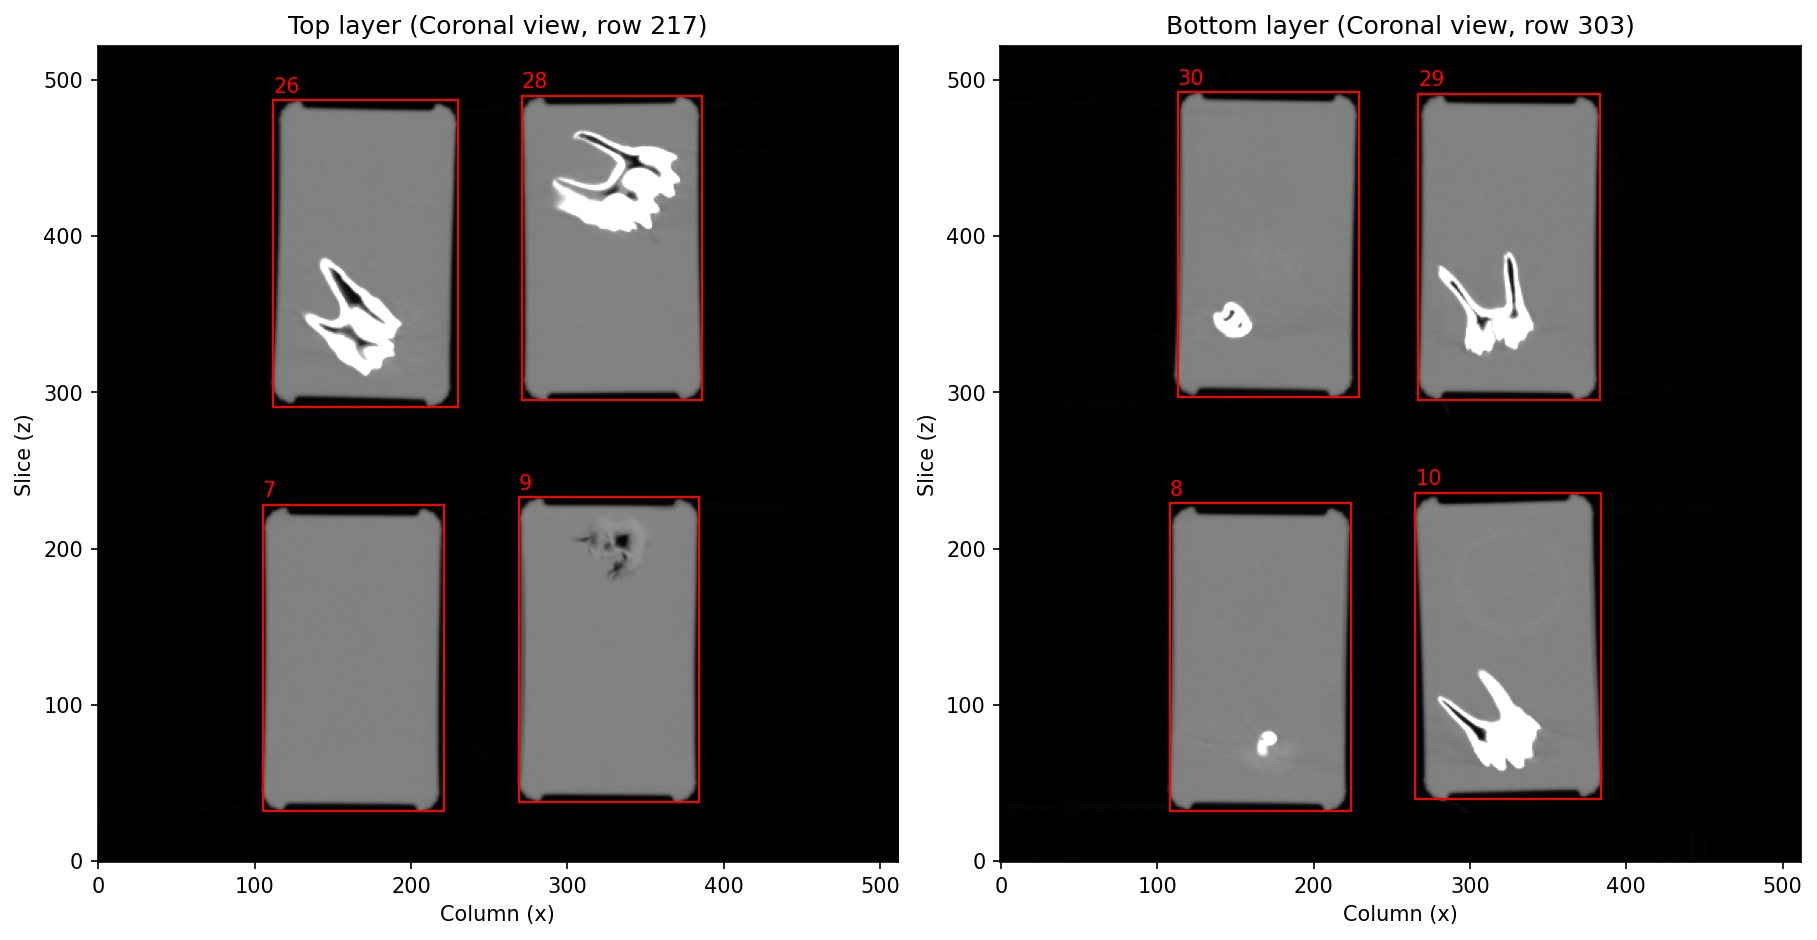

In [79]:
# ---------------------------------------------------------------------------
# 1. Find the vertical centre (y) of each box filling
# ---------------------------------------------------------------------------
centers_y = {}                          # Dictionary: label -> centre row
for i in fills:
    sz, sy, sx = boxes[i - 1]           # Bounding box of region i (labels start at 1, list index at 0)
    center = (sy.start + sy.stop) / 2   # Middle row of the box
    centers_y[i] = center

# ---------------------------------------------------------------------------
# 2. Split into top and bottom layer
# ---------------------------------------------------------------------------
# The median of the 8 centres falls between the two layers (4 above, 4 below)
y_split = np.median(list(centers_y.values()))

top_layer = []
bottom_layer = []
for i in fills:
    if centers_y[i] < y_split:          # Smaller row number = higher up in the axial image
        top_layer.append(i)
    else:
        bottom_layer.append(i)

layers = {"Top layer": top_layer, "Bottom layer": bottom_layer}

# ---------------------------------------------------------------------------
# 3. Plot each layer as a coronal slice with the detected boxes
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 6), dpi=150, constrained_layout=True)

for ax, (name, ids) in zip(axes, layers.items()):      # One subplot per layer

    # Choose a row through the middle of this layer
    layer_centers = []
    for i in ids:
        layer_centers.append(centers_y[i])
    y_show = int(np.mean(layer_centers))

    # Coronal slice: all slices (z) and columns (x) at row y_show
    ax.imshow(ct[:, y_show, :], cmap="gray", vmin=-1000, vmax=1000, origin="lower")

    # Draw a rectangle and a label for each box in this layer
    for i in ids:
        sz, sy, sx = boxes[i - 1]

        x_left   = sx.start                 # Left edge (column)
        z_bottom = sz.start                 # Bottom edge (slice), bottom because origin="lower"
        width    = sx.stop - sx.start       # Width in columns
        height   = sz.stop - sz.start       # Height in slices

        rect = plt.Rectangle((x_left, z_bottom), width, height, fill=False, edgecolor="r")
        ax.add_patch(rect)

        ax.text(x_left, sz.stop + 5, str(i), color="r", fontsize=10)   # Label just above the box

    ax.set_title(f"{name} ({ct_names[1]} view, row {y_show})")
    ax.set_xlabel("Column (x)")
    ax.set_ylabel("Slice (z)")

plt.show()

---

## Step 3: Crop phantom 3A

The CT contains eight phantoms (A1–A8) in two layers of four, with the long axis of each box along the scanner table. Our phantom is box A3.

Box A3 was located from photos of the setup and the DICOM header:
- **Layer:** A3 is stacked on top of A1 → top layer (smaller row numbers in the axial images).
- **Position along the table:** A3/A1 is the stack closest to the gantry. The scan is head first (PatientPosition = HFS), so the gantry end corresponds to high slice numbers.
- **Side of the table:** the photo is taken from the left side of the bed, seen from the foot end, which is the patient's right in an HFS scan. With ImageOrientationPatient = [1, 0, 0, 0, 1, 0], the column index increases toward the patient's left, so A3 is at low column numbers.

The box contents measure about 24 HU, consistent with a water-like filling.

In [80]:
# ---------------------------------------------------------------------------
# 1. Find A3: top layer, highest z (gantry end), lowest x (patient's right)
# ---------------------------------------------------------------------------
top = layers["Top layer"]

a3_label = max(top, key=lambda i: boxes[i - 1][0].start - boxes[i - 1][2].start)
sz, sy, sx = boxes[a3_label - 1]      # Bounding box of A3's filling

# ---------------------------------------------------------------------------
# 2. Expand the bounding box with a margin, so the box walls are included
# ---------------------------------------------------------------------------
MARGIN = 10                              # voxels, so the box walls (outside the filling) are included

n_z, n_y, n_x = ct.shape                 # Volume size, so the crop doesn't go outside the image

z_start = max(sz.start - MARGIN, 0)      # Don't go below 0
z_stop  = min(sz.stop  + MARGIN, n_z)    # Don't go past the last slice
y_start = max(sy.start - MARGIN, 0)      
y_stop  = min(sy.stop  + MARGIN, n_y)
x_start = max(sx.start - MARGIN, 0)
x_stop  = min(sx.stop  + MARGIN, n_x)   

Z_RANGE = (z_start, z_stop)              # Range of slices (z) to crop
Y_RANGE = (y_start, y_stop)              # Range of rows (y) to crop
X_RANGE = (x_start, x_stop)              # Range of columns (x) to crop

# ---------------------------------------------------------------------------
# 3. Crop the volume
# ---------------------------------------------------------------------------
ct_a3 = ct[z_start:z_stop, y_start:y_stop, x_start:x_stop]

# ---------------------------------------------------------------------------
# 4. Print the result
# ---------------------------------------------------------------------------
dz, dy, dx = ct_spacing                 
n_z_a3, n_y_a3, n_x_a3 = ct_a3.shape

print(f"A3 = label {a3_label}")
print(f"Crop: z {Z_RANGE}, y {Y_RANGE}, x {X_RANGE}")
print(f"Shape (voxels): {ct_a3.shape}")
print(f"Size (mm): {n_z_a3 * dz:.1f} x {n_y_a3 * dy:.1f} x {n_x_a3 * dx:.1f}")

# ---------------------------------------------------------------------------
# 5. Check the crop in the viewer
# ---------------------------------------------------------------------------
viewer(ct_a3, ct_spacing, names=ct_names, title="CT - phantom A3", modality="CT")

A3 = label 26
Crop: z (281, 497), y (173, 262), x (102, 240)
Shape (voxels): (216, 89, 138)
Size (mm): 135.0 x 52.1 x 80.9


---

## Step 4: Save the crop

The cropped volume of phantom A3 is saved to `data/processed/ct_a3.npz`, so later notebooks don't need to load and crop the full CT again. The file contains:

- `volume`: the cropped CT volume in HU (slices, rows, cols)
- `spacing`: voxel spacing in mm (dz, dy, dx)
- `crop`: the crop ranges in the original volume (z, y, x), so the crop can be reproduced

In [81]:
# ---------------------------------------------------------------------------
# Save the cropped volume, its spacing and the crop ranges
# ---------------------------------------------------------------------------
PROCESSED.mkdir(parents=True, exist_ok=True)          # Create data/processed if it doesn't exist
out_file = PROCESSED / "ct_a3.npz"

np.savez(
    out_file,
    volume=ct_a3,                                     # Cropped CT in HU
    spacing=np.array(ct_spacing),                     # (dz, dy, dx) in mm
    crop=np.array([Z_RANGE, Y_RANGE, X_RANGE]),       # Crop ranges in the full volume
)
print(f"Saved: {out_file}  ({out_file.stat().st_size / 1e6:.1f} MB)")

# ---------------------------------------------------------------------------
# Check: load it again and compare with what we saved
# ---------------------------------------------------------------------------
d = np.load(out_file)
print("Volume shape:", d["volume"].shape)
print("Spacing (mm):", d["spacing"])
print("Crop (z, y, x):", d["crop"].tolist())
print("Identical to ct_a3:", np.array_equal(d["volume"], ct_a3))

Saved: ../data/processed/ct_a3.npz  (10.6 MB)
Volume shape: (216, 89, 138)
Spacing (mm): [0.625    0.585938 0.585938]
Crop (z, y, x): [[281, 497], [173, 262], [102, 240]]
Identical to ct_a3: True


---

## Step 5: Objects in phantom A3

### 5a: Visual inspection

Phantom A3 is inspected slice by slice in all three planes, using the soft tissue window (small HU differences) and the bone window (dense structures).

In [82]:
viewer(ct_a3, ct_spacing, names=ct_names, title="CT - phantom A3", modality="CT")

**Observations:**
- ...


### 5b: Segmentation of the dense object

**Box interior.** The interior of box A3 is defined as the convex hull of the filling in each axial slice, shrunk by 2 voxels to avoid partial-volume voxels at the walls. Using the convex hull ensures that objects touching the walls are included.

In [83]:
# Interior of box A3: convex hull of the filling per axial slice, shrunk slightly
filling = (labels == a3_label)[z_start:z_stop, y_start:y_stop, x_start:x_stop]

inside = np.zeros_like(filling)
for z in range(filling.shape[0]):
    if filling[z].any():                                # Skip slices outside the box
        inside[z] = convex_hull_image(filling[z])
inside = ndimage.binary_erosion(inside, iterations=2)   # Avoid partial-volume voxels at the walls

**HU distribution and threshold.** The maximum storable value, `CLIP_HU`, is calculated from the DICOM header (`BitsStored`, `PixelRepresentation`, `RescaleSlope` and `RescaleIntercept`). Voxels at this value are clipped, so their true attenuation is higher.

The HU distribution inside the box shows a narrow peak around 0 HU (the water-like filling) and a broad tail up to `CLIP_HU` (the dense object). The threshold `DENSE_HU` is placed where the filling peak has dropped to the level of the tail, so it separates the two.

BitsStored: 16, signed: True, slope: 1.0, intercept: -1024.0
Maximum storable value: 31743 HU  |  maximum in the data: 3071 HU


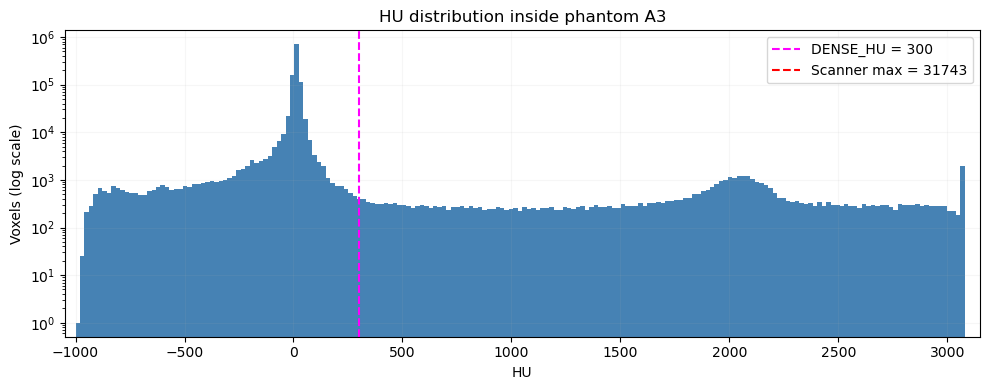

In [84]:
DENSE_HU = 300      # Threshold for the dense object (HU)

# --- Maximum storable value from the DICOM header ---
ds = first_header(CT_HELICAL)
bits      = int(ds.BitsStored)
signed    = int(ds.PixelRepresentation) == 1        # 0 = unsigned, 1 = signed
slope     = float(ds.RescaleSlope)
intercept = float(ds.RescaleIntercept)

stored_max = 2**(bits - 1) - 1 if signed else 2**bits - 1
CLIP_HU = stored_max * slope + intercept

print(f"BitsStored: {bits}, signed: {signed}, slope: {slope}, intercept: {intercept}")
print(f"Maximum storable value: {CLIP_HU:.0f} HU  |  maximum in the data: {ct.max():.0f} HU")

# --- Histogram of HU values inside the box ---
hu_inside = ct_a3[inside]

plt.figure(figsize=(10, 4), dpi=100)
plt.hist(hu_inside, bins=200, range=(-1000, 3100), log=True, color="SteelBlue")
plt.axvline(DENSE_HU, c="magenta", ls="--", label=f"DENSE_HU = {DENSE_HU}")
plt.axvline(CLIP_HU, c="red", ls="--", label=f"Scanner max = {CLIP_HU:.0f}")
plt.xlabel("HU")
plt.ylabel("Voxels (log scale)")
plt.title("HU distribution inside phantom A3")
plt.xlim(-1050, 3150)
plt.legend()
plt.grid(alpha=0.1)
plt.tight_layout()
plt.show()

**Segmentation.** The dense object is segmented as voxels inside the box above `DENSE_HU`. Only the largest connected region is kept, and enclosed cavities are filled, so they count as part of the object.

In [85]:
# 1. Dense voxels inside the box
dense = inside & (ct_a3 > DENSE_HU)

# 2. Keep only the largest connected region (the object)
dense_labels, _ = ndimage.label(dense)
sizes = np.bincount(dense_labels.ravel())[1:]           # Size of each region (skip background 0)
obj = dense_labels == (np.argmax(sizes) + 1)            # +1 because labels start at 1
print(f"{len(sizes)} dense regions found")
print("Largest sizes (voxels):", sorted(sizes, reverse=True)[:5])

# 3. Fill enclosed cavities, so they count as part of the object
obj = ndimage.binary_fill_holes(obj)

print(f"Object: {obj.sum()} voxels")

1 dense regions found
Largest sizes (voxels): [np.int64(52007)]
Object: 52037 voxels


### 5c: Measurements of the dense object

The segmented object is measured as:
- **Volume:** number of voxels × voxel volume.
- **Bounding box:** extent along each image axis. This is an upper limit for tilted or irregular objects, not the true size along the object's own axes.
- **HU statistics:** mean, median and standard deviation of all voxels in the object. The median is less affected by clipped voxels than the mean.
- **Cavity:** the share of voxels below `DENSE_HU`, i.e. enclosed regions filled in during segmentation.
- **Clipped:** the share of voxels at the scanner's maximum value (`CLIP_HU`). Their true attenuation is higher, so the mean HU is a lower limit.

In [86]:
dz, dy, dx = ct_spacing
voxel_volume = dz * dy * dx                             # mm³ per voxel

hu = ct_a3[obj]                                         # HU values of all object voxels
sz, sy, sx = ndimage.find_objects(obj.astype(int))[0]   # Bounding box of the object

obj_table = pd.DataFrame([{
    "Voxels":              int(obj.sum()),
    "Volume (mm³)":        round(obj.sum() * voxel_volume, 0),
    "Bounding box z (mm)": round((sz.stop - sz.start) * dz, 1),
    "Bounding box y (mm)": round((sy.stop - sy.start) * dy, 1),
    "Bounding box x (mm)": round((sx.stop - sx.start) * dx, 1),
    "Mean HU":             round(float(hu.mean()), 0),
    "Median HU":           round(float(np.median(hu)), 0),
    "Std HU":              round(float(hu.std()), 0),
    "Cavity (%)":          round(100 * (hu < DENSE_HU).mean(), 1),
    "Clipped (%)":         round(100 * (hu >= CLIP_HU).mean(), 1),
}], index=["Object 1"])

display(obj_table)
save_table(obj_table.reset_index(names="Object"), "ct_a3_object")

,Voxels,Volume (mm³),Bounding box z (mm),Bounding box y (mm),Bounding box x (mm),Mean HU,Median HU,Std HU,Cavity (%),Clipped (%)
Object 1,52037,11166.0,50.0,19.9,43.9,1814.0,1969.0,746.0,0.1,0.0


Saved table: results/ct_a3_object.csv


### 5d: Check the segmentation

The outline of the segmented object is drawn on slices through its centre, to check that it follows the visible edge.